In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El cuadro de prelaciones, las duraciones planificadas (semanas) y el presupuesto de cada actividad (BAC, k€) de un proyecto se adjuntan; el coste planificado se reparte uniformemente en la duración. La línea base aprobada por el cliente fija el inicio en la semana 0 y el fin en la semana 22.

In [4]:
#| tbl-cap: "Línea base aprobada"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 6       , 20 ),
    ('B'     , '---'      , 4       , 30 ),
    ('C'     , '---'      , 2       , 20 ),
    ('D'     , 'A,B,C'    , 1       , 70 ),
    ('E'     , 'A,C'      , 7       , 60 ),
    ('F'     , 'D,E'      , 6       , 60 ),
    ('G'     , 'D'        , 7       , 70 ),
    ('H'     , 'F'        , 3       , 70 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,6,20
B,---,4,30
C,---,2,20
D,"A,B,C",1,70
E,"A,C",7,60
F,"D,E",6,60
G,D,7,70
H,F,3,70


El proyecto arrancó 2 semanas tarde porque el cliente entregó los permisos con retraso; desde entonces todo avanza al ritmo previsto. Al final de la semana 12 el seguimiento es el siguiente (semanas trabajadas, coste incurrido y avance verificado).

In [5]:
#| tbl-cap: "Seguimiento al final de la semana 12"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 6              , 20, 100      ),
    ('B'     , 4              , 30, 100      ),
    ('C'     , 2              , 20, 100      ),
    ('D'     , 1              , 70, 100      ),
    ('E'     , 4              , 34, 57       ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 3              , 30, 43       ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento

,actual_duration,AC,performed
activity,,,
A,6,20,100
B,4,30,100
C,2,20,100
D,1,70,100
E,4,34,57
F,0,0,0
G,3,30,43
H,0,0,0


> **De: Jefe de proyecto**
> El SPI sale mal por culpa del cliente. Vamos a desplazar la línea base 2 semanas —es lo que de verdad pasó— y el informe sale con SPI = 1. No hace falta abrir una solicitud de cambio: es un ajuste técnico, no un cambio de alcance.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C9 — Línea base y control de cambios.** La línea base sólo cambia mediante una solicitud de cambio aprobada; medir el avance contra una línea base reescrita sin aprobación es presentar un índice fuera de contexto (C3). *(cf. PMBOK 8, dominio de gobernanza (control integrado de cambios).)*
- **C3 — Información fuera de contexto.** Presentar un dato cierto en un marco que lleva a una conclusión equivocada (un índice calculado sobre una línea base reescrita). *(cf. Código Ético del PMI, 5.3.1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [6]:
pregunta_1 = "1. (A) Calcule PV, EV, AC, SV, SPI, CV y CPI en la semana 12 contra la línea base aprobada y la fecha de fin prevista.  "
pregunta_2 = "2. (A) Repita el cálculo contra la línea base desplazada 2 semanas. ¿Qué indicadores cambian y cuáles no? ¿Cambia la fecha de fin prevista?  "
pregunta_3 = "3. (B) Según el criterio de referencia, ¿puede el jefe de proyecto desplazar la línea base como propone? ¿Qué forma de engaño sería el informe con SPI = 1 y qué procedimiento haría legítimo el cambio?  "
pregunta_4 = "4. (C) ¿Qué informe envía y qué propone al cliente? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule PV, EV, AC, SV, SPI, CV y CPI en la semana 12 contra la línea base aprobada y la fecha de fin prevista.  

2. (A) Repita el cálculo contra la línea base desplazada 2 semanas. ¿Qué indicadores cambian y cuáles no? ¿Cambia la fecha de fin prevista?  

3. (B) Según el criterio de referencia, ¿puede el jefe de proyecto desplazar la línea base como propone? ¿Qué forma de engaño sería el informe con SPI = 1 y qué procedimiento haría legítimo el cambio?  

4. (C) ¿Qué informe envía y qué propone al cliente? Aplique la rúbrica de la lección.  

# Resolución

In [7]:
semana_control, desplazamiento = 12, 2
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
BAC_total = float(datos_proyecto['BAC'].sum())
def indicadores(seguimiento, calendario_plan, semana):
    datos_vg = pd.concat([datos_proyecto, seguimiento], axis=1)
    detalle = detalle_valor_ganado(datos_vg, calendario_plan, semana)
    PV, EV, AC = float(detalle['PV_i'].sum()), float(detalle['EV_i'].sum()), float(detalle['AC'].sum())
    return detalle, pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV': EV - AC, 'SV': EV - PV, 'CPI': EV / AC, 'SPI': EV / PV})

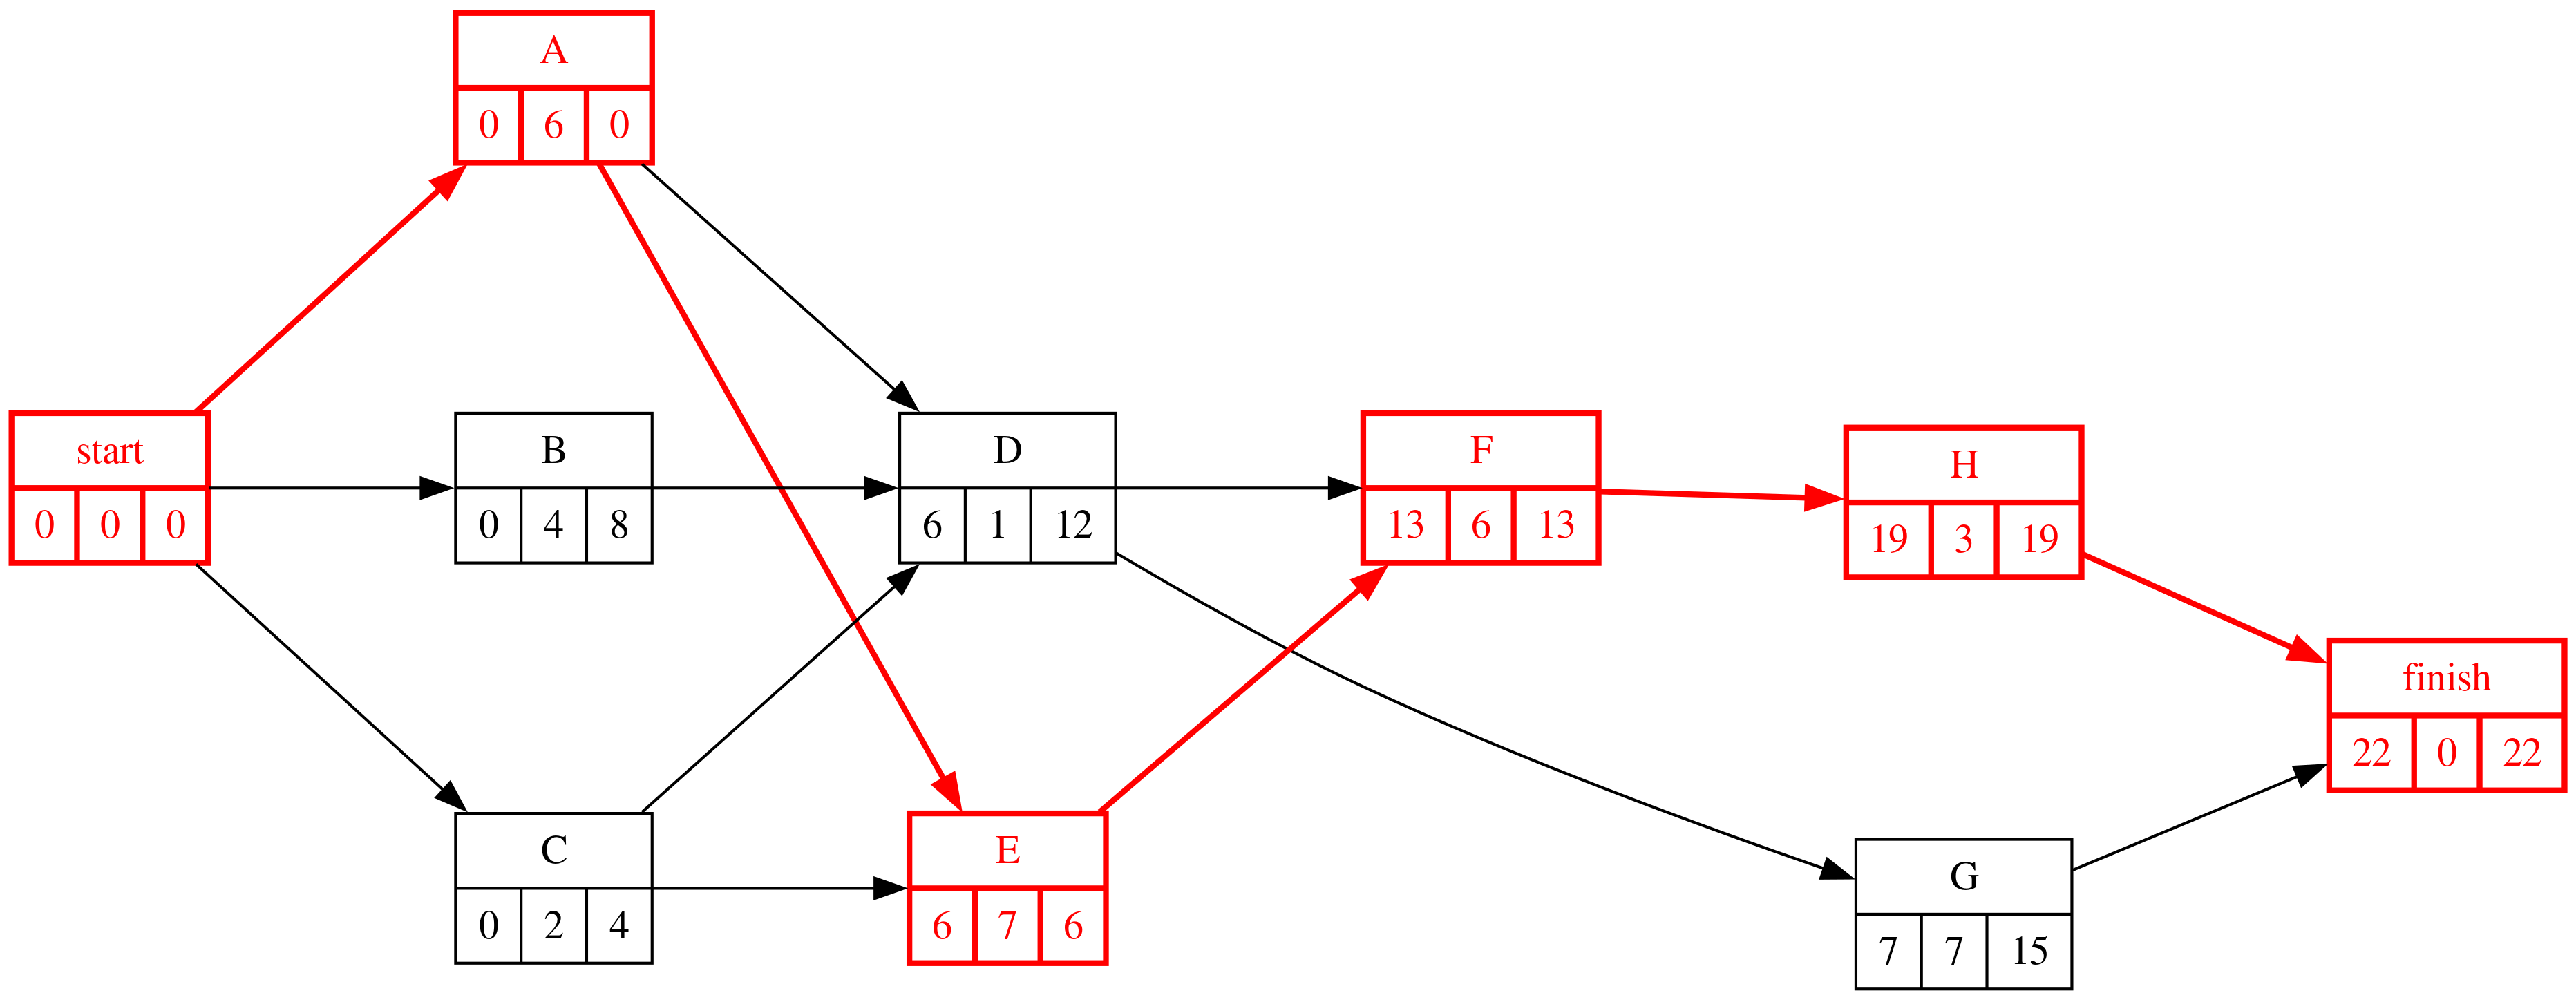

In [9]:
#| fig-cap: "Grafo Roy de la línea base"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [8]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{D} = \max\{0+6,\ 0+4,\ 0+2\} = 6$ &nbsp; (A, B, C)
- $T_{E} = \max\{0+6,\ 0+2\} = 6$ &nbsp; (A, C)
- $T_{F} = \max\{6+1,\ 6+7\} = 13$ &nbsp; (D, E)
- $T_{G} = 6+1 = 7$ &nbsp; (D)
- $T_{H} = 13+6 = 19$ &nbsp; (F)
- $T_{\mathrm{Fin}} = \max\{7+7,\ 19+3\} = 22$ &nbsp; (G, H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 22$
- $T_{H}^{*} = 22-3 = 19$ &nbsp; (Fin)
- $T_{G}^{*} = 22-7 = 15$ &nbsp; (Fin)
- $T_{F}^{*} = 19-6 = 13$ &nbsp; (H)
- $T_{E}^{*} = 13-7 = 6$ &nbsp; (F)
- $T_{D}^{*} = \min\{13-1,\ 15-1\} = 12$ &nbsp; (F, G)
- $T_{C}^{*} = \min\{12-2,\ 6-2\} = 4$ &nbsp; (D, E)
- $T_{B}^{*} = 12-4 = 8$ &nbsp; (D)
- $T_{A}^{*} = \min\{12-6,\ 6-6\} = 0$ &nbsp; (D, E)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 8-0,\ 4-0\} = 0$ &nbsp; (A, B, C)

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. (A) Calcule PV, EV, AC, SV, SPI, CV y CPI en la semana 12 contra la línea base aprobada y la fecha de fin prevista.  

In [11]:
#| tbl-cap: "PV, EV y AC contra la línea base aprobada"
#| label: tbl-detalleBase
detalle_base, ind_base = indicadores(seguimiento, calendario, semana_control)
display(detalle_base[['BAC', 'planificado hasta la semana', 'PV = BAC·fracción', 'realizado (%)', 'EV = BAC·%', 'AC']])
ind_base.round(3).to_frame('línea base aprobada').T

,BAC,planificado hasta la semana,PV = BAC·fracción,realizado (%),EV = BAC·%,AC
A,20.0,6 de 6,20·1.00 = 20.0,100,20·1.00 = 20.0,20.0
B,30.0,4 de 4,30·1.00 = 30.0,100,30·1.00 = 30.0,30.0
C,20.0,2 de 2,20·1.00 = 20.0,100,20·1.00 = 20.0,20.0
D,70.0,1 de 1,70·1.00 = 70.0,100,70·1.00 = 70.0,70.0
E,60.0,6 de 7,60·0.86 = 51.4,57,60·0.57 = 34.2,34.0
F,60.0,0 de 6,60·0.00 = 0.0,0,60·0.00 = 0.0,0.0
G,70.0,5 de 7,70·0.71 = 50.0,43,70·0.43 = 30.1,30.0
H,70.0,0 de 3,70·0.00 = 0.0,0,70·0.00 = 0.0,0.0


,PV,EV,AC,CV,SV,CPI,SPI
línea base aprobada,241.429,204.3,204.0,0.3,-37.129,1.001,0.846


In [12]:
fin_previsto = duracion + desplazamiento
Markdown(f'''SPI = {ind_base["SPI"]:.2f}, SV = {ind_base["SV"]:.1f} k€ (CPI = {ind_base["CPI"]:.2f}: el coste va según lo hecho). Como el retraso es de arranque y el ritmo es el previsto, la fecha de fin prevista es la semana **{fin_previsto}** ({desplazamiento} más que la línea base).''')

SPI = 0.85, SV = -37.1 k€ (CPI = 1.00: el coste va según lo hecho). Como el retraso es de arranque y el ritmo es el previsto, la fecha de fin prevista es la semana **24** (2 más que la línea base).

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Repita el cálculo contra la línea base desplazada 2 semanas. ¿Qué indicadores cambian y cuáles no? ¿Cambia la fecha de fin prevista?  

In [14]:
#| tbl-cap: "Lo mismo contra la línea base desplazada (PV calculado en la semana t − desplazamiento)"
#| label: tbl-detalleDesplazada
calendario_desplazado = calendario.copy()
for col in ['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio']:
    calendario_desplazado[col] = calendario[col] + desplazamiento
detalle_desp, ind_desp = indicadores(seguimiento, calendario_desplazado, semana_control)
comparacion = pd.DataFrame({'línea base aprobada': ind_base, 'línea base desplazada': ind_desp})
comparacion.round(3)

,línea base aprobada,línea base desplazada
PV,241.429,204.286
EV,204.300,204.300
AC,204.000,204.000
CV,0.300,0.300
SV,-37.129,0.014
CPI,1.001,1.001
SPI,0.846,1.000


In [15]:
Markdown(f'''Sólo cambia PV (y con él SV y SPI, que pasa a {ind_desp["SPI"]:.2f}); EV, AC, CV y CPI no se mueven. La fecha de fin prevista sigue siendo la semana {fin_previsto}: el retraso ha desaparecido del informe, no del proyecto.''')

Sólo cambia PV (y con él SV y SPI, que pasa a 1.00); EV, AC, CV y CPI no se mueven. La fecha de fin prevista sigue siendo la semana 24: el retraso ha desaparecido del informe, no del proyecto.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. (B) Según el criterio de referencia, ¿puede el jefe de proyecto desplazar la línea base como propone? ¿Qué forma de engaño sería el informe con SPI = 1 y qué procedimiento haría legítimo el cambio?  

**C9.** La línea base es un compromiso aprobado con el cliente; cambiarla exige una **solicitud de cambio aprobada** por el control integrado de cambios, no un «ajuste técnico» del jefe de proyecto. Que la causa del retraso sea del cliente no cambia el procedimiento: es justamente el motivo de una solicitud de cambio (o de una reclamación) en la que el cliente reconoce las 2 semanas y se aprueba la nueva fecha de fin (24). Sin ese trámite, un informe con SPI = 1 es **C3**: una cifra correcta contra una referencia que nadie ha aprobado, presentada como si fuera el plan. Con el trámite, el mismo SPI = 1 es legítimo, porque la referencia es la nueva línea base aprobada.

In [17]:
preguntas_test = [
    ('Una línea base puede cambiarse…', ['mediante una solicitud de cambio aprobada', 'por decisión del jefe de proyecto si la causa es del cliente', 'nunca', 'siempre que no cambie el alcance'],
     'C9: la línea base sólo cambia por el control integrado de cambios.'),
    ('Al desplazar la línea base, el indicador que NO cambia es…', ['CPI', 'PV', 'SV', 'SPI'],
     'PV depende de la línea base; EV y AC no, así que CV y CPI se mantienen.'),
    ('Un informe con SPI = 1 contra una línea base desplazada sin aprobación es…', ['C3, información fuera de contexto', 'C1, afirmación falsa', 'correcto: el retraso era del cliente', 'C6, conflicto de interés'],
     'La cifra es correcta contra una referencia que no es el plan aprobado.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — línea base reescrita')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — línea base reescrita

::Ética 19 — línea base reescrita P1::Una línea base puede cambiarse… {=mediante una solicitud de cambio aprobada ~por decisión del jefe de proyecto si la causa es del cliente ~nunca ~siempre que no cambie el alcance ####C9: la línea base sólo cambia por el control integrado de cambios.}

::Ética 19 — línea base reescrita P2::Al desplazar la línea base, el indicador que NO cambia es… {~SPI =CPI ~SV ~PV ####PV depende de la línea base; EV y AC no, así que CV y CPI se mantienen.}

::Ética 19 — línea base reescrita P3::Un informe con SPI = 1 contra una línea base desplazada sin aprobación es… {~C6, conflicto de interés =C3, información fuera de contexto ~C1, afirmación falsa ~correcto: el retraso era del cliente ####La cifra es correcta contra una referencia que no es el plan aprobado.}



## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. (C) ¿Qué informe envía y qué propone al cliente? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Informe: SPI 0.85 contra la línea base aprobada, con la causa documentada (permisos entregados 2 semanas tarde) y la fecha prevista 24. Propuesta al cliente: solicitud de cambio por causa imputable al cliente que mueva la línea base 2 semanas y, si procede, la compensación de costes de la espera; aprobada, los informes siguientes miden contra la nueva línea base. Lo que no cabe: el «ajuste técnico» silencioso, que además deja al contratista sin la prueba de que el retraso no es suyo.